# Влияние начальной инициализации центров в KMeans

**Цель:** исследовать, как выбор начальных центров влияет на качество и устойчивость KMeans на фиксированных данных, сравнить `random` и `k-means++` и оценить влияние числа повторных стартов.

**План:**
1. Теория KMeans, способы инициализации и показатели качества.
2. Два фиксированных набора данных.
3. Один запуск KMeans и проверка воспроизводимости.
4. Сравнение `random` и `k-means++` при одном старте.
5. Влияние числа повторных стартов.
6. Явное задание начальных центров.
7. Сопоставление результатов и визуализация разбиений.
8. Выводы.

## 1. Теория

`KMeans` разбивает точки $x_1, \ldots, x_n$ на $k$ кластеров $C_1, \ldots, C_k$ с центрами $\mu_1, \ldots, \mu_k$. Минимизируется сумма квадратов расстояний до назначенных центров:

$$J = \sum_{j=1}^{k}\sum_{x_i \in C_j}\|x_i-\mu_j\|^2.$$

После выбора начальных центров алгоритм чередует два действия: назначение каждой точки ближайшему центру и пересчёт центра как среднего точек непустого кластера:

$$c_i = \arg\min_{1\leq j\leq k}\|x_i-\mu_j\|^2,
\qquad
\mu_j = \frac{1}{|C_j|}\sum_{x_i\in C_j}x_i.$$

Итерации продолжаются до выполнения условия остановки или достижения лимита. Начальные центры задают исходное положение оптимизации, поэтому на одних и тех же точках возможны разные конечные разбиения.

| инициализация | выбор начальных центров |
| --- | --- |
| `random` | случайные объекты исходного набора |
| `k-means++` | выбор с учётом расстояний до уже выбранных центров |
| массив координат | заранее заданные положения центров |

Параметр `n_init` задаёт число стартов за один вызов KMeans. В scikit-learn 1.9.1 метод `KMeans.fit` сохраняет первый результат и заменяет его, когда очередной старт даёт меньшую inertia и другое разбиение точек. При сравнении разбиений перестановка номеров кластеров допускается.

**Показатели.** Inertia соответствует целевой функции $J$ и сравнивается внутри одного набора при фиксированном $k$. ARI показывает согласованность с группами генератора независимо от перестановки номеров кластеров. `n_iter_` характеризует число итераций выбранного решения; при нескольких стартах это не сумма итераций всех запусков.

**Условия сравнения.** Данные генерируются с `data_seed=42`; список `seeds` меняет только случайность начальных центров моделей. Число кластеров, точки и их порядок фиксированы внутри каждого набора. Рабочий каталог — `src/`; настройки всех экспериментов определены ниже.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

In [2]:
data_seed = 42
shuffle = True

data_settings = {
    "simple": {
        "n_samples": 600,
        "centers": np.array([[-5, -4], [0, 5], [5, -3]]),
        "cluster_std": 0.8,
    },
    "grid": {
        "n_samples": 900,
        "centers": np.array([(x, y) for x in (-4, 0, 4) for y in (-4, 0, 4)]),
        "cluster_std": 0.65,
    },
}

init_methods = ["random", "k-means++"]
seeds = list(range(50))
n_init_values = [1, 5, 10]
model_params = {
    "algorithm": "lloyd",
    "max_iter": 300,
    "tol": 1e-4,
}

In [3]:
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
})

## 2. Данные

Для сравнения с помощью `make_blobs` созданы два двумерных набора.

- `simple` — контрольный набор с тремя центрами генерации: `(-5, -4)`, `(0, 5)`, `(5, -3)` и `cluster_std=0.8`;
- `grid` — основной набор с девятью центрами на решётке: каждая координата принимает значения `-4`, `0`, `4`, `cluster_std=0.65`.

Каждый набор генерируется один раз до обучения с `random_state=42` и `shuffle=True`. В `datasets` отдельно хранятся признаки, метки групп генератора и заданное число кластеров. Все модели используют эти же массивы.

In [4]:
datasets = {}

for name, settings in data_settings.items():
    data, labels = make_blobs(
        **settings,
        random_state=data_seed,
        shuffle=shuffle,
    )
    datasets[name] = {
        "data": data,
        "labels": labels,
        "k": len(settings["centers"]),
    }

In [5]:
rows = []

for name, dataset in datasets.items():
    groups, counts = np.unique(dataset["labels"], return_counts=True)
    rows.append({
        "Набор": name,
        "Объектов": dataset["data"].shape[0],
        "Признаков": dataset["data"].shape[1],
        "Групп": len(groups),
        "Объектов в группах": ", ".join(str(count) for count in counts),
    })

data_summary = pd.DataFrame(rows).set_index("Набор")
data_summary

,Объектов,Признаков,Групп,Объектов в группах
Набор,,,,
simple,600,2,3,"200, 200, 200"
grid,900,2,9,"100, 100, 100, 100, 100, 100, 100, 100, 100"


Таблица рассчитана по созданным массивам; размеры групп перечислены в порядке возрастания меток генератора. В `simple` каждая из трёх групп содержит 200 точек, в `grid` каждая из девяти — 100.

Оба признака имеют сопоставимый масштаб, поэтому используются исходные координаты. Метки генератора нужны для ARI и изображения исходных групп; обучение KMeans получает только признаки.

Центры генерации описывают исходные распределения. Начальные центры KMeans определяют старт оптимизации; в основной серии эти координаты модель выбирает самостоятельно. Ниже цвет обозначает группу генератора.

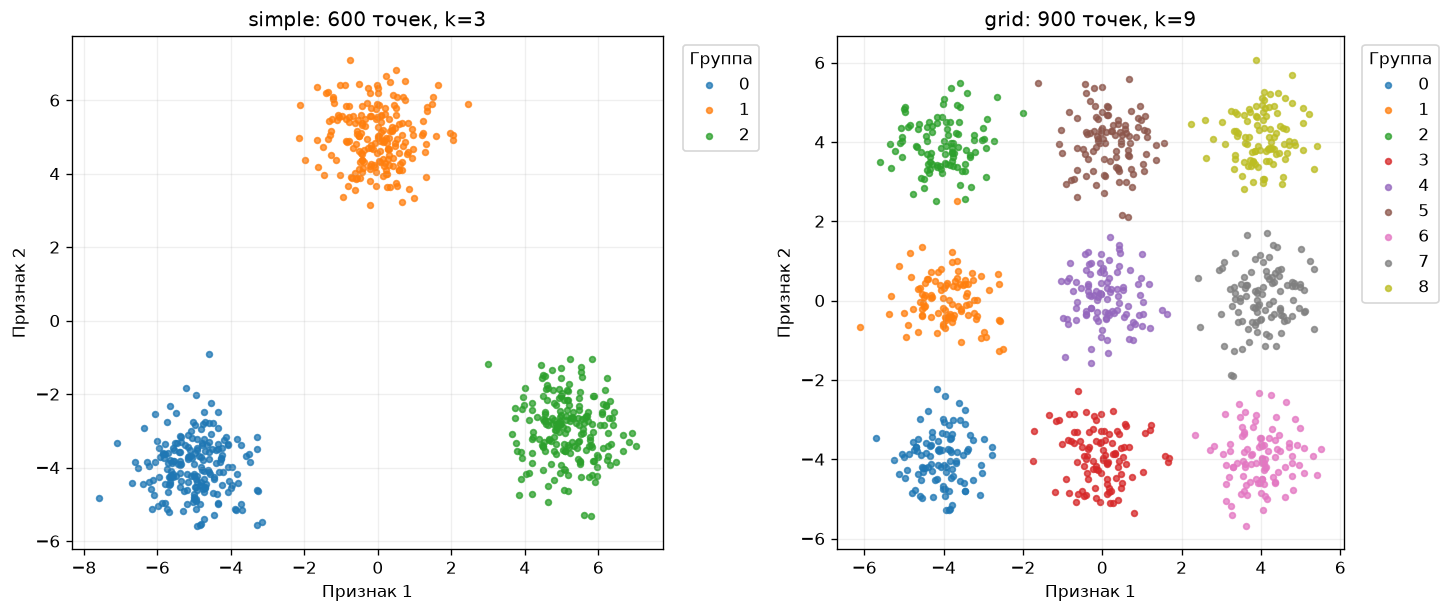

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
colors = plt.get_cmap("tab10")

for ax, (name, dataset) in zip(axes, datasets.items()):
    data = dataset["data"]
    labels = dataset["labels"]

    for group in np.unique(labels):
        points = data[labels == group]
        ax.scatter(
            points[:, 0],
            points[:, 1],
            s=12,
            alpha=0.75,
            color=colors(int(group)),
            label=str(group),
        )

    ax.set_title(f"{name}: {len(data)} точек, k={dataset['k']}")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(title="Группа", loc="upper left", bbox_to_anchor=(1.02, 1))

fig.savefig(figures_dir / "01_data.png", dpi=160)
plt.show()

В контрольном наборе расположены три облака точек; основной набор содержит девять групп на решётке. Каждый набор сравнивается отдельно при своём фиксированном числе кластеров.

Цвета показывают известные группы генератора. Разбиения KMeans приведены в следующих разделах.

## 3. Один запуск KMeans

Для каждого запуска создаётся новый `KMeans` с явно заданными числом кластеров, способом инициализации, `n_init` и `random_state`. Параметры остановки берутся из общей настройки `model_params`.

В `fit` передаются только признаки. После обучения inertia и число итераций берутся из модели, а ARI отдельно рассчитывается по меткам генератора.

Сначала выполняются четыре пробных запуска: оба способа инициализации на обоих наборах при `n_init=1` и `random_state=0`. Модели сохраняются в `trial_models`, результаты — в `trial_results`. Эти пробы не добавляются отдельными повторными строками в основную статистику.

In [7]:
def run_kmeans(data, k, init, n_init, seed):
    model = KMeans(
        n_clusters=k,
        init=init,
        n_init=n_init,
        random_state=seed,
        **model_params,
    )
    model.fit(data)
    return model

In [8]:
trial_models = {}
rows = []

for name, dataset in datasets.items():
    for init in init_methods:
        model = run_kmeans(
            dataset["data"],
            dataset["k"],
            init=init,
            n_init=1,
            seed=0,
        )
        trial_models[(name, init)] = model
        rows.append({
            "dataset": name,
            "init": init,
            "n_init": model.n_init,
            "seed": model.random_state,
            "inertia": model.inertia_,
            "ari": adjusted_rand_score(dataset["labels"], model.labels_),
            "n_iter": model.n_iter_,
        })

trial_results = pd.DataFrame(rows)
trial_results.round({"inertia": 3, "ari": 4})

,dataset,init,n_init,seed,inertia,ari,n_iter
0,simple,random,1,0,744.491,1.0000,3
1,simple,k-means++,1,0,744.491,1.0000,2
2,grid,random,1,0,1407.877,0.8351,8
3,grid,k-means++,1,0,731.494,0.9975,3


На `simple` оба способа получили разбиение с inertia 744.491 и ARI = 1. Для `random` потребовалось 3 итерации, для `k-means++` — 2.

На `grid` при `random` получены inertia 1407.877 и ARI 0.8351, при `k-means++` — 731.494 и 0.9975. Число итераций составило 8 и 3 соответственно. Для этих данных и выбранного старта `k-means++` нашёл решение с меньшей целевой функцией и более высоким ARI.

В каждом случае рассмотрен один старт при `n_init=1`, `random_state=0`. Для оценки разброса и сравнения способов в следующем разделе приведена серия из 50 значений случайности модели.

## 4. Сравнение способов инициализации

На каждом фиксированном наборе выполнены по 50 запусков `random` и `k-means++` при `n_init=1`, `seed=0…49`. Меняется только случайность начальных центров; точки, их порядок, число кластеров и параметры остановки сохраняются.

Каждый запуск записывается отдельной строкой, включая худшие исходы. Полная таблица `single_results` содержит 200 записей и семь столбцов: набор, способ инициализации, число стартов, значение случайности модели, inertia, ARI и число итераций. Ниже показаны первые пять строк; копия `baseline_results` сохраняется для сверки при расширении серии.

In [9]:
rows = []

for name, dataset in datasets.items():
    for init in init_methods:
        for seed in seeds:
            model = run_kmeans(
                dataset["data"],
                dataset["k"],
                init=init,
                n_init=1,
                seed=seed,
            )
            rows.append({
                "dataset": name,
                "init": init,
                "n_init": model.n_init,
                "seed": model.random_state,
                "inertia": model.inertia_,
                "ari": adjusted_rand_score(dataset["labels"], model.labels_),
                "n_iter": model.n_iter_,
            })

single_results = pd.DataFrame(rows).sort_values(
    ["dataset", "init", "n_init", "seed"]
).reset_index(drop=True)
baseline_results = single_results.copy()
single_results.head()

,dataset,init,n_init,seed,inertia,ari,n_iter
0,grid,k-means++,1,0,731.493986,0.99749,3
1,grid,k-means++,1,1,731.493986,0.99749,3
2,grid,k-means++,1,2,731.493986,0.99749,3
3,grid,k-means++,1,3,731.493986,0.99749,3
4,grid,k-means++,1,4,731.493986,0.99749,3


In [10]:
def summarize_results(results):
    return results.groupby(["dataset", "init", "n_init"]).agg(
        runs=("seed", "size"),
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", lambda values: values.std(ddof=1)),
        inertia_median=("inertia", "median"),
        inertia_min=("inertia", "min"),
        inertia_max=("inertia", "max"),
        ari_mean=("ari", "mean"),
        ari_std=("ari", lambda values: values.std(ddof=1)),
        n_iter_mean=("n_iter", "mean"),
        n_iter_max=("n_iter", "max"),
    ).reset_index()

single_summary = summarize_results(single_results)

single_summary[[
    "dataset", "init", "runs", "inertia_mean", "inertia_std",
    "inertia_min", "inertia_max", "ari_mean", "ari_std",
]].round(4)

,dataset,init,runs,inertia_mean,inertia_std,inertia_min,inertia_max,ari_mean,ari_std
0,grid,k-means++,50,731.5013,0.0251,731.4940,731.5857,0.9975,0.0000
1,grid,random,50,1271.4763,443.7826,731.4940,2308.0475,0.8757,0.0949
2,simple,k-means++,50,744.4913,0.0000,744.4913,744.4913,1.0000,0.0000
3,simple,random,50,2495.8707,3788.2817,744.4913,11120.0895,0.9000,0.2155


В каждой строке сводки объединены 50 запусков одного способа на одном наборе. Стандартное отклонение рассчитано с `ddof=1` и характеризует чувствительность к начальным центрам на фиксированных данных. Средние и крайние значения inertia сравниваются отдельно внутри каждого набора.

На `simple` у `random` средняя inertia равна 2495.8707, стандартное отклонение — 3788.2817, медиана — 744.4913. Диапазон inertia — 744.4913–11120.0895, ARI — 0.4437–1.0000. В 9 из 50 запусков ARI оказался ниже 1: отдельные неудачные старты заметно увеличили среднее. У `k-means++` все 50 запусков дали ARI = 1 и inertia 744.4913.

На `grid` у `random` средняя inertia равна 1271.4763 при стандартном отклонении 443.7826; диапазон — 731.4940–2308.0475. У `k-means++` средняя inertia составляет 731.5013, SD — 0.0251, диапазон — 731.4940–731.5857. Средний ARI равен 0.8757 и 0.9975 соответственно; у `random` он меняется от 0.6891 до 0.9975, у `k-means++` все 50 значений равны 0.9975 в отображаемой точности. В этой серии `k-means++` устойчивее по inertia на обоих наборах.

Значения SD на уровне вычислительной погрешности отображаются как нулевые при округлении. Сводки показаны с четырьмя знаками, в отдельных примерах inertia — с тремя и ARI — с четырьмя. Исходные метрики и CSV хранятся без предварительного округления. В следующем разделе приведено влияние повторных стартов на качество и разброс.

## 5. Число повторных стартов

Серия расширена до `n_init=1`, `5`, `10` при тех же данных, двух способах инициализации и 50 значениях случайности модели. Проверенные 200 результатов при `n_init=1` берутся из `baseline_results`; дополнительно обучаются 400 моделей для пяти и десяти стартов.

Для каждого вызова KMeans в таблицу записывается одно выбранное решение. Параметры `algorithm`, `max_iter`, `tol`, данные и порядок объектов сохраняются. В общей таблице 600 записей, по 200 на каждое `n_init`.

В основной серии выполнены 3200 внутренних стартов: `2 × 2 × 50 × (1 + 5 + 10)`. Пробные обучения и диагностические повторы в это число не входят. `n_iter_` относится к выбранному решению и не описывает суммарную работу всех стартов.

In [11]:
rows = baseline_results.to_dict(orient="records")

for n_init in n_init_values[1:]:
    for name, dataset in datasets.items():
        for init in init_methods:
            for seed in seeds:
                model = run_kmeans(
                    dataset["data"],
                    dataset["k"],
                    init=init,
                    n_init=n_init,
                    seed=seed,
                )
                rows.append({
                    "dataset": name,
                    "init": init,
                    "n_init": model.n_init,
                    "seed": model.random_state,
                    "inertia": model.inertia_,
                    "ari": adjusted_rand_score(dataset["labels"], model.labels_),
                    "n_iter": model.n_iter_,
                })

results = pd.DataFrame(rows).sort_values(
    ["dataset", "init", "n_init", "seed"]
).reset_index(drop=True)
results.groupby("n_init").size().rename("Запусков")

n_init
1     200
5     200
10    200
Name: Запусков, dtype: int64

In [12]:
summary = summarize_results(results)
summary[[
    "dataset", "init", "n_init", "runs",
    "inertia_mean", "inertia_std", "ari_mean", "ari_std",
]].round(4)

,dataset,init,n_init,runs,inertia_mean,inertia_std,ari_mean,ari_std
0,grid,k-means++,1,50,731.5013,0.0251,0.9975,0.0000
1,grid,k-means++,5,50,731.5013,0.0251,0.9975,0.0000
2,grid,k-means++,10,50,731.5013,0.0251,0.9975,0.0000
3,grid,random,1,50,1271.4763,443.7826,0.8757,0.0949
4,grid,random,5,50,745.0489,95.7946,0.9942,0.0236
5,grid,random,10,50,731.5013,0.0251,0.9975,0.0000
6,simple,k-means++,1,50,744.4913,0.0000,1.0000,0.0000
7,simple,k-means++,5,50,744.4913,0.0000,1.0000,0.0000
8,simple,k-means++,10,50,744.4913,0.0000,1.0000,0.0000
9,simple,random,1,50,2495.8707,3788.2817,0.9000,0.2155


In [13]:
results.to_csv("results.csv", index=False)
summary.to_csv("summary.csv", index=False)

На `simple` у `random` средняя inertia снизилась с 2495.8707 при одном старте до 744.4913 при пяти и десяти стартах. При `n_init=5` и `10` все 50 результатов дали ARI = 1; разброс inertia находится на уровне вычислительной погрешности.

На `grid` у `random` средняя inertia составила 1271.4763, 745.0489 и 731.5013 для `n_init=1`, `5`, `10`. Соответствующие SD равны 443.7826, 95.7946 и 0.0251. При пяти стартах максимальная inertia ещё достигала 1408.8718; при десяти диапазон сузился до 731.4940–731.5857, средний ARI вырос до 0.9975.

У `k-means++` увеличение `n_init` до 5 и 10 не изменило среднюю inertia, её SD и средний ARI в отображаемой точности. Например, на `grid` при `seed=7` все три значения `n_init` дали inertia 731.586 и ARI 0.9975. Эти наблюдения относятся к выбранным данным и 50 значениям `random_state`.

При запуске полная таблица записывается в `results.csv`, сводка — в `summary.csv`. В каждой из 12 групп объединены 50 запусков одного способа с одним `n_init` на одном наборе. Статистики рассчитываются общей функцией `summarize_results` с `ddof=1`. Файлы пересоздаются без предварительного округления. `n_iter_` описывает выбранное решение; число итераций всех стартов в этой величине не суммируется.

## 6. Явное задание начальных центров

На том же фиксированном наборе `grid` сравниваются два массива из девяти начальных центров:

1. `spread` — копия координат решётки генератора.
2. `concentrated` — координаты девяти разных объектов, ближайших к точке `(-4, -4)`. Устойчивая сортировка сохраняет порядок исходных индексов при равных расстояниях.

Исходные координаты сохраняются в `initial_centers`, а в KMeans передаётся их отдельная копия. Оба запуска используют `n_init=1`, `random_state=0` и общие параметры остановки. Начальная inertia рассчитывается как сумма квадратов расстояний точек до ближайшего стартового центра.

`spread` использует известное расположение групп генератора. Это отдельная учебная иллюстрация; её результаты не входят в основную статистику `random` и `k-means++`. Данные заново не генерируются.

In [14]:
grid_data = datasets["grid"]["data"]
grid_labels = datasets["grid"]["labels"]
grid_k = datasets["grid"]["k"]

squared_distances = ((grid_data - np.array([-4, -4])) ** 2).sum(axis=1)
order = np.argsort(squared_distances, kind="stable")
initial_centers = {
    "spread": data_settings["grid"]["centers"].copy(),
    "concentrated": grid_data[order[:grid_k]].copy(),
}

In [15]:
manual_models = {}
rows = []

for start, centers in initial_centers.items():
    squared_distances = ((grid_data[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    inertia_before = squared_distances.min(axis=1).sum()
    model = run_kmeans(
        grid_data,
        grid_k,
        init=centers.copy(),
        n_init=1,
        seed=0,
    )
    manual_models[start] = model
    rows.append({
        "start": start,
        "inertia_before": inertia_before,
        "inertia": model.inertia_,
        "ari": adjusted_rand_score(grid_labels, model.labels_),
        "n_iter": model.n_iter_,
    })

manual_results = pd.DataFrame(rows)
manual_results.to_csv("manual_starts.csv", index=False)
manual_results.round({"inertia_before": 3, "inertia": 3, "ari": 4})

,start,inertia_before,inertia,ari,n_iter
0,spread,741.161,731.494,0.9975,2
1,concentrated,46433.481,2188.012,0.6919,26


Слева показаны исходные группы генератора и сохранённые начальные центры — чёрные ромбы. Справа точки окрашены по меткам KMeans, конечные центры отмечены крестами. Номера и цвета кластеров KMeans могут отличаться от групп генератора.

Во всех четырёх панелях одинаковы пределы и масштаб координат. Близкие начальные центры `concentrated` частично перекрываются на рисунке.

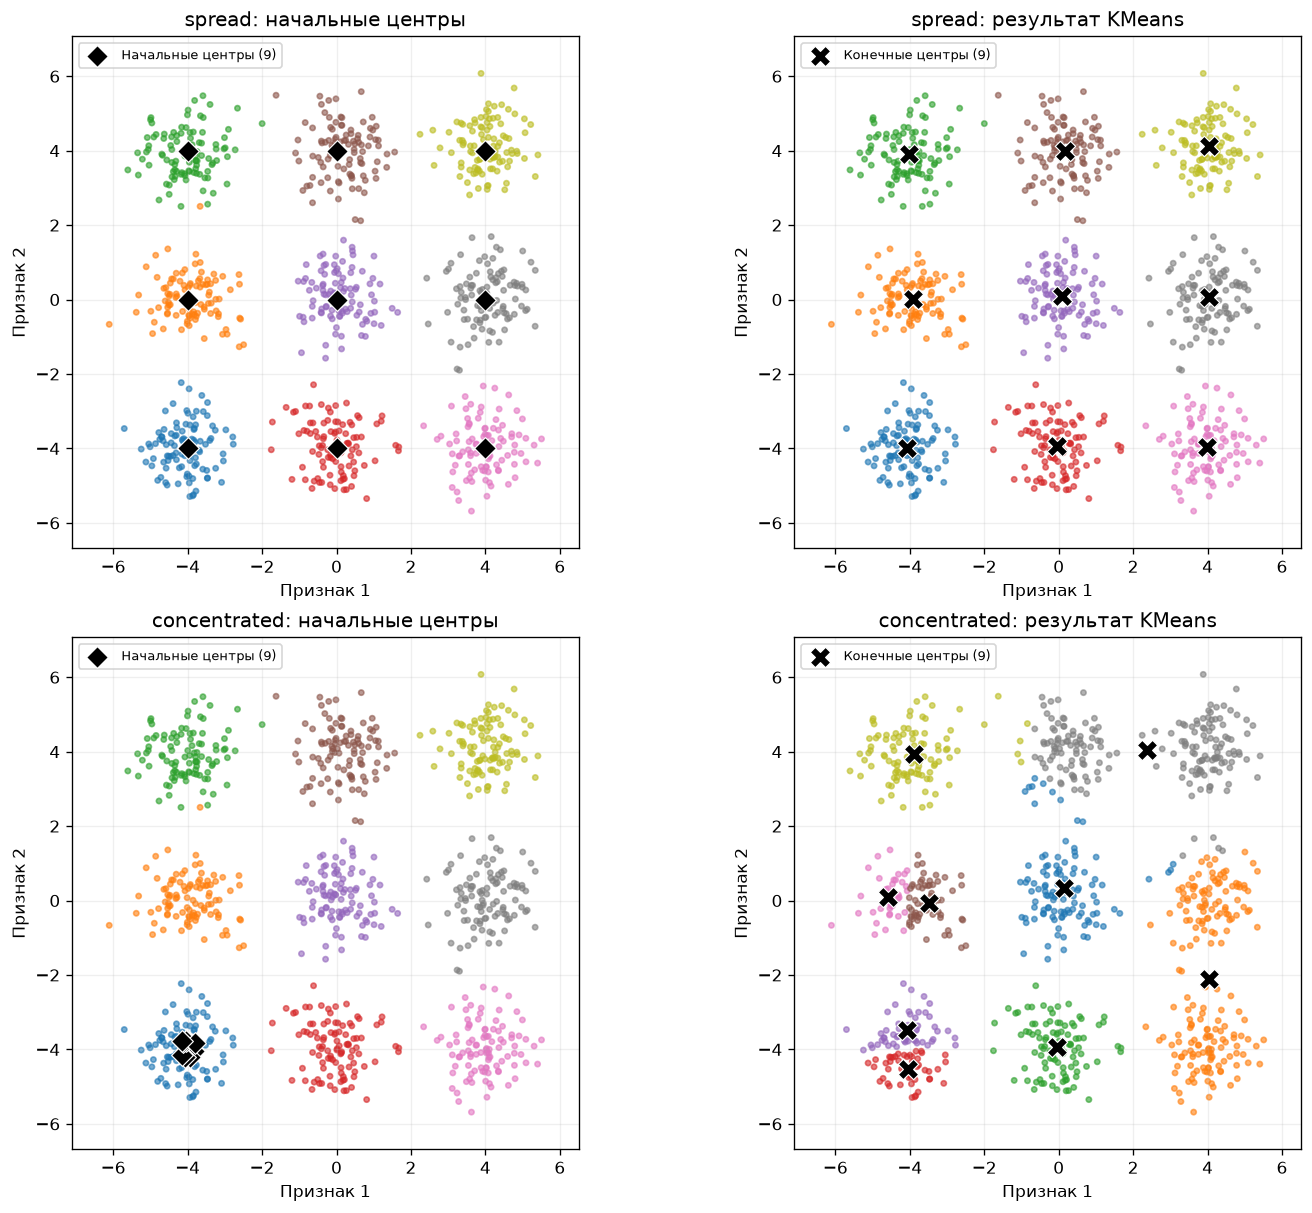

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
x_limits = (grid_data[:, 0].min() - 1, grid_data[:, 0].max() + 1)
y_limits = (grid_data[:, 1].min() - 1, grid_data[:, 1].max() + 1)

for row, (start, centers) in enumerate(initial_centers.items()):
    model = manual_models[start]
    start_ax = axes[row, 0]
    final_ax = axes[row, 1]

    start_ax.scatter(
        grid_data[:, 0], grid_data[:, 1], c=colors(grid_labels), s=10, alpha=0.6,
    )
    start_ax.scatter(
        centers[:, 0], centers[:, 1], marker="D", s=85,
        color="black", edgecolors="white", linewidths=0.7,
        label="Начальные центры (9)", zorder=3,
    )
    final_ax.scatter(
        grid_data[:, 0], grid_data[:, 1], c=colors(model.labels_), s=10, alpha=0.6,
    )
    final_ax.scatter(
        model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker="X", s=150,
        color="black", edgecolors="white", linewidths=0.7,
        label="Конечные центры (9)", zorder=3,
    )
    start_ax.set_title(f"{start}: начальные центры")
    final_ax.set_title(f"{start}: результат KMeans")

    for ax in axes[row]:
        ax.set_xlim(x_limits)
        ax.set_ylim(y_limits)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("Признак 1")
        ax.set_ylabel("Признак 2")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left", fontsize=8)

fig.savefig(figures_dir / "05_initial_centers.png", dpi=160)
plt.show()

Для `spread` начальная inertia составила 741.161, конечная — 731.494, ARI — 0.9975; потребовалось 2 итерации. Для `concentrated` начальная inertia равна 46433.481, конечная — 2188.012, ARI — 0.6919; потребовалось 26 итераций.

На этих данных сосредоточенные рядом с одной группой начальные центры привели к большей конечной inertia, меньшему ARI и большему числу итераций. На рисунке часть групп генератора объединена, а некоторые разделены между несколькими кластерами. Оба запуска выполнялись на одних и тех же точках при одинаковом числе кластеров и параметрах остановки. Результат иллюстрирует влияние старта; `spread` использует дополнительные сведения о расположении групп.

При запуске результаты двух конфигураций записываются в `manual_starts.csv`, а рисунок сохраняется в `figures/05_initial_centers.png`. В основной таблице остаются 600 запусков стандартных способов инициализации.

## 7. Сопоставление результатов

Статистические графики строятся по `results` и `summary` без ручной подстановки значений. Распределения отобраны при `n_init=1`, зависимости от числа стартов используют все три значения `n_init`.

### Распределения одиночных стартов

В каждой панели показаны 50 результатов `random` и 50 результатов `k-means++` на одном фиксированном наборе. Коробка показывает межквартильный диапазон и медиану; усы доходят до крайних значений в пределах 1,5 межквартильного размаха от коробки. Поверх нанесены все отдельные результаты, включая выходящие за усы. Точки немного разнесены по горизонтали для видимости совпадающих значений. Inertia сравнивается внутри одного набора.

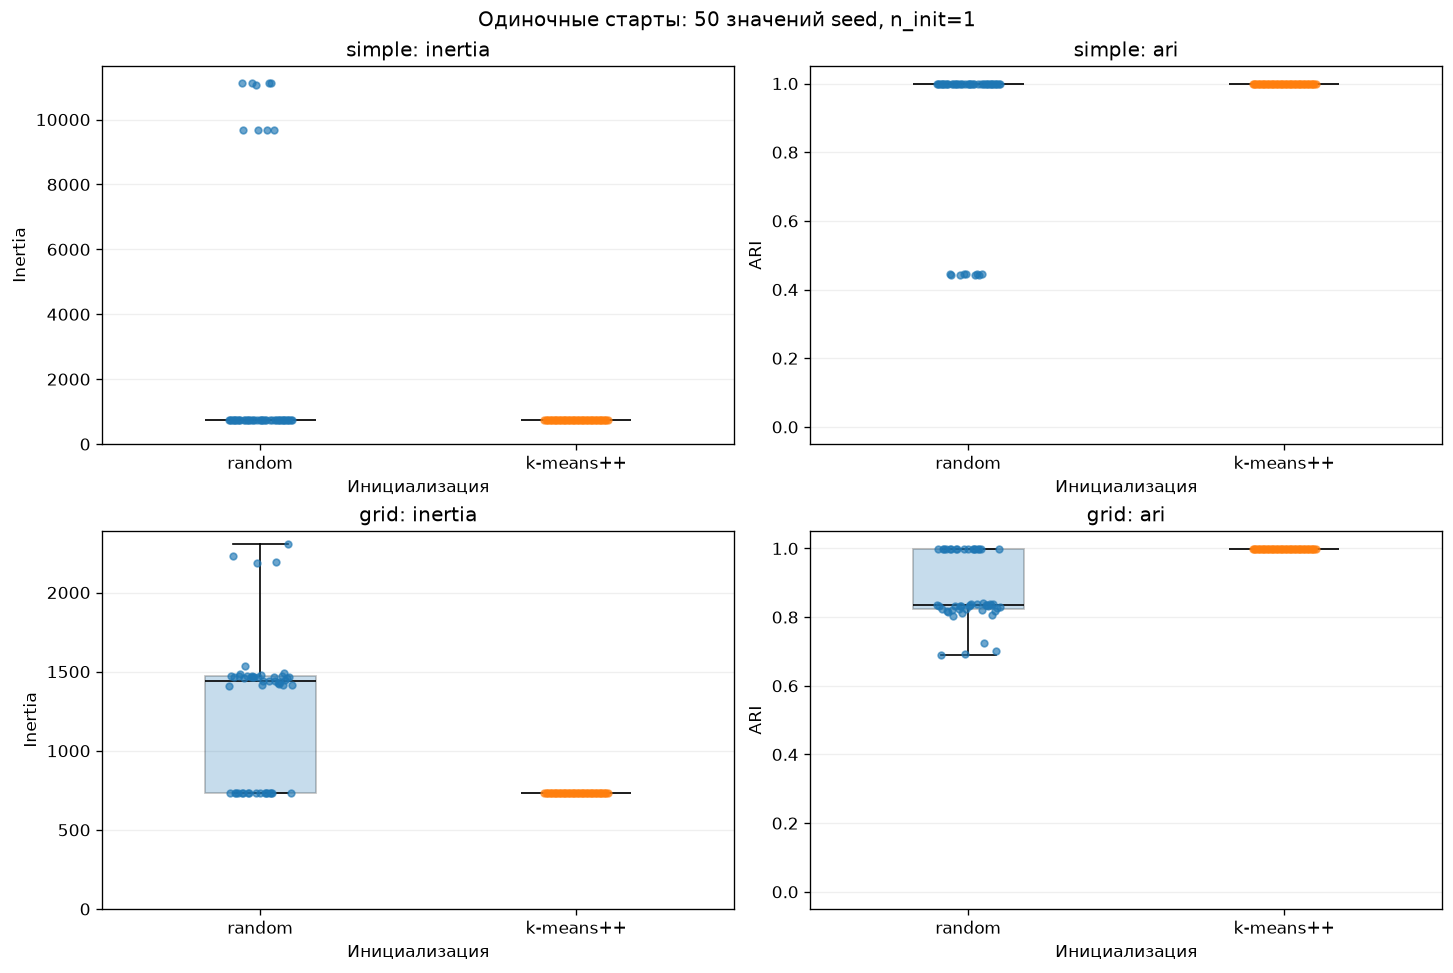

In [17]:
method_colors = {"random": "tab:blue", "k-means++": "tab:orange"}
single_runs = results.loc[results["n_init"] == 1]
single_fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")

for row, name in enumerate(datasets):
    for column, metric in enumerate(["inertia", "ari"]):
        ax = axes[row, column]
        samples = [
            single_runs.loc[
                (single_runs["dataset"] == name)
                & (single_runs["init"] == init)
            ].sort_values("seed")[metric].to_numpy()
            for init in init_methods
        ]
        boxes = ax.boxplot(
            samples, tick_labels=init_methods, widths=0.35,
            patch_artist=True, showfliers=False,
            medianprops={"color": "black"},
        )

        for position, (init, values, box) in enumerate(
            zip(init_methods, samples, boxes["boxes"]), start=1,
        ):
            box.set_facecolor(method_colors[init])
            box.set_alpha(0.25)
            offsets = np.linspace(-0.1, 0.1, len(values))
            ax.scatter(
                position + offsets, values, s=16,
                color=method_colors[init], alpha=0.65, zorder=3,
            )

        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("Инициализация")
        ax.set_ylabel("Inertia" if metric == "inertia" else "ARI")
        ax.grid(axis="y", alpha=0.2)
        if metric == "ari":
            ax.set_ylim(-0.05, 1.05)
        else:
            ax.set_ylim(bottom=0)

single_fig.suptitle("Одиночные старты: 50 значений seed, n_init=1")
single_fig.savefig(figures_dir / "02_single_start.png", dpi=160)
plt.show()

На `simple` большинство результатов `random` совпадают с `k-means++`, но отдельные старты дают значительно большую inertia и меньший ARI. На `grid` у `random` заметен разброс, а результаты `k-means++` сосредоточены около меньшей inertia и большего ARI. Коробка может выглядеть как линия, когда квартильные значения совпадают; отдельные точки при этом сохраняются.

### Средние показатели и число стартов

Каждая точка следующего рисунка — среднее по 50 запускам при заданных наборе, инициализации и `n_init`. Интервалы показывают среднее ± одно стандартное отклонение с `ddof=1`. Они описывают разброс по начальным центрам, а не доверительный интервал или разброс между выборками.

Среднее ± SD может выходить за допустимый диапазон самой метрики. Такие интервалы показаны полностью; это не границы возможных значений inertia или ARI. Разные маркеры и стили линий помогают различать совпадающие средние.

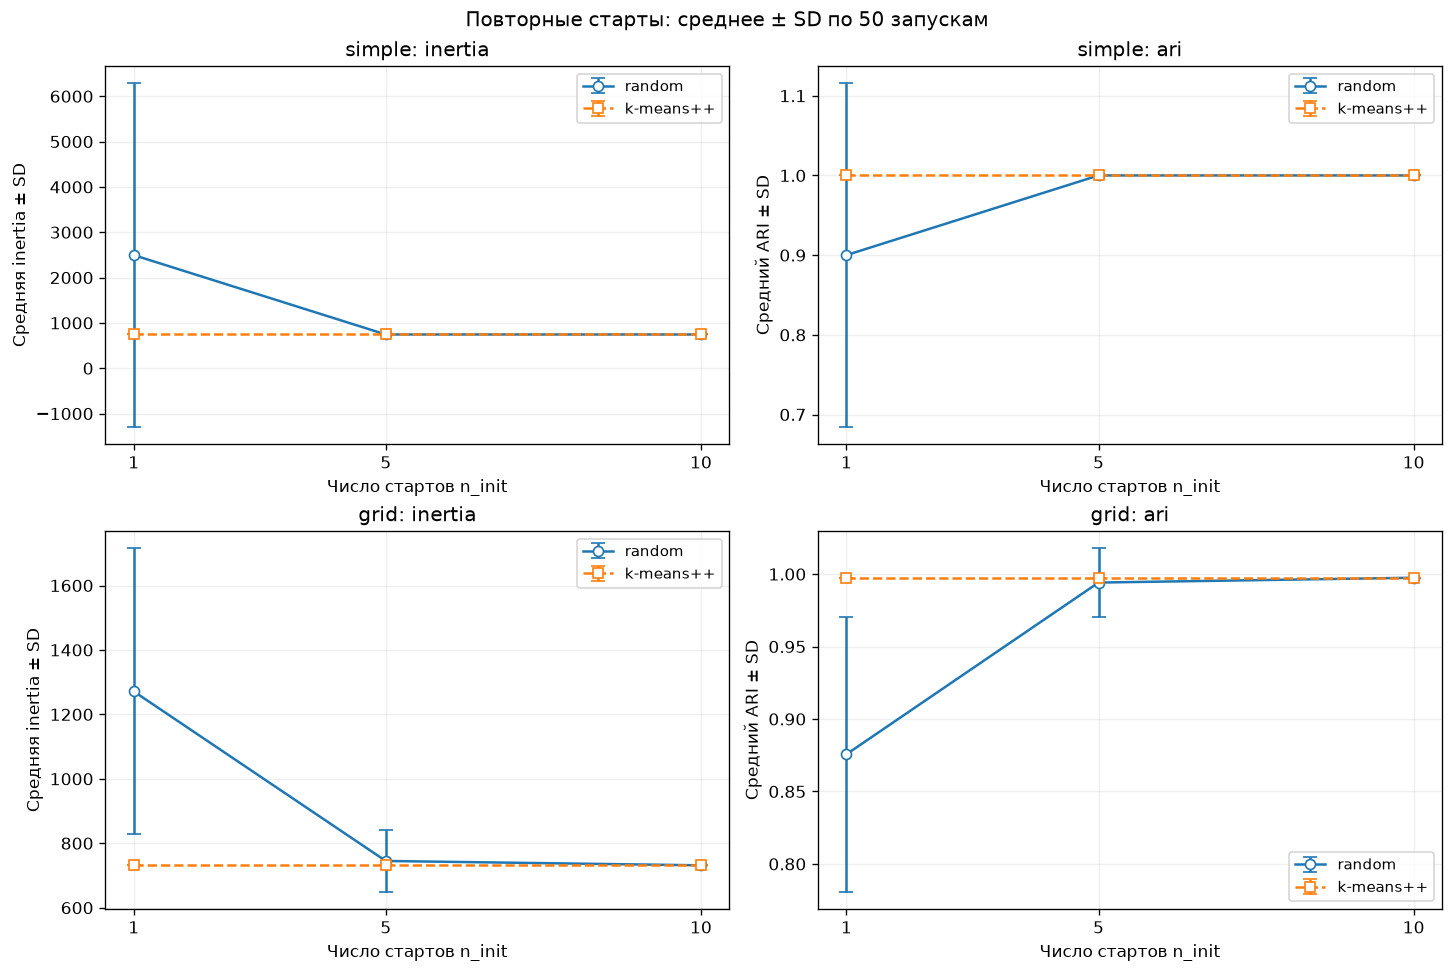

In [18]:
restart_fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")

for row, name in enumerate(datasets):
    for column, metric in enumerate(["inertia", "ari"]):
        ax = axes[row, column]
        for init, marker, style in zip(init_methods, ["o", "s"], ["-", "--"]):
            values = summary.loc[
                (summary["dataset"] == name) & (summary["init"] == init)
            ].sort_values("n_init")
            ax.errorbar(
                values["n_init"], values[f"{metric}_mean"],
                yerr=values[f"{metric}_std"],
                marker=marker, linestyle=style, color=method_colors[init],
                markerfacecolor="white", markersize=6, capsize=4,
                label=init,
            )

        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("Число стартов n_init")
        ax.set_ylabel("Средняя inertia ± SD" if metric == "inertia" else "Средний ARI ± SD")
        ax.set_xticks(n_init_values)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=9)

restart_fig.suptitle("Повторные старты: среднее ± SD по 50 запускам")
restart_fig.savefig(figures_dir / "03_restarts.png", dpi=160)
plt.show()

Повторные старты уменьшают среднюю inertia и её разброс у `random` на обоих наборах. На `simple` при пяти стартах все результаты дают ARI = 1. На `grid` при десяти стартах приведённые средние inertia и ARI и их SD совпадают с `k-means++` в отображаемой точности, поэтому линии частично перекрываются. Малое стандартное отклонение может быть незаметно на масштабе осей.

### Крайние результаты одной серии

Для иллюстрации выбраны минимальная и максимальная inertia среди всех 50 строк `dataset=grid`, `init=random`, `n_init=1`. При равенстве inertia выбирается меньший `seed`. Для каждого примера модель обучается заново с параметрами выбранной строки; эти два обучения не добавляются в `results`.

Ниже приведены выбранные записи. Это крайние исходы заданной серии, а не оценка типичного результата и не доказательство глобального оптимума.

In [19]:
grid_results = results.loc[
    (results["dataset"] == "grid")
    & (results["init"] == "random")
    & (results["n_init"] == 1)
]
best_result = grid_results.sort_values(["inertia", "seed"]).iloc[0]
worst_result = grid_results.sort_values(
    ["inertia", "seed"], ascending=[False, True],
).iloc[0]
partition_results = pd.DataFrame([best_result, worst_result]).reset_index(drop=True)
partition_results.insert(0, "case", ["Минимальная inertia", "Максимальная inertia"])

partition_models = {}
for row in partition_results.itertuples(index=False):
    partition_models[row.case] = run_kmeans(
        grid_data,
        grid_k,
        init=row.init,
        n_init=int(row.n_init),
        seed=int(row.seed),
    )

partition_results[["case", "seed", "inertia", "ari", "n_iter"]].round({
    "inertia": 3, "ari": 4,
})

,case,seed,inertia,ari,n_iter
0,Минимальная inertia,1,731.494,0.9975,5
1,Максимальная inertia,46,2308.047,0.7026,8


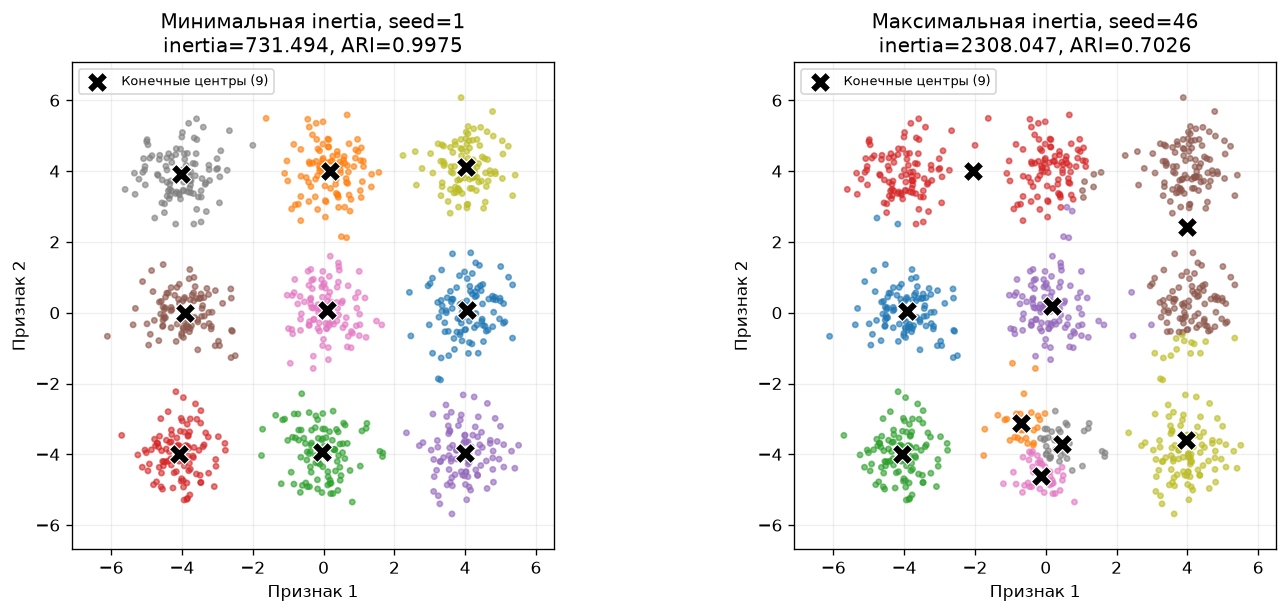

In [20]:
partition_fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
x_limits = (grid_data[:, 0].min() - 1, grid_data[:, 0].max() + 1)
y_limits = (grid_data[:, 1].min() - 1, grid_data[:, 1].max() + 1)

for ax, row in zip(axes, partition_results.itertuples(index=False)):
    model = partition_models[row.case]
    ax.scatter(
        grid_data[:, 0], grid_data[:, 1], c=colors(model.labels_), s=10, alpha=0.6,
    )
    ax.scatter(
        model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
        marker="X", s=150, color="black", edgecolors="white", linewidths=0.7,
        label="Конечные центры (9)", zorder=3,
    )
    ax.set_title(
        f"{row.case}, seed={row.seed}\n"
        f"inertia={row.inertia:.3f}, ARI={row.ari:.4f}"
    )
    ax.set_xlim(x_limits)
    ax.set_ylim(y_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", fontsize=8)

partition_fig.savefig(figures_dir / "04_partitions.png", dpi=160)
plt.show()

Минимальная inertia в этой серии получена при `seed=1`: 731.494, ARI 0.9975, 5 итераций. Максимальная — при `seed=46`: 2308.047, ARI 0.7026, 8 итераций. На рисунке с большей inertia часть исходных групп объединена, а одна группа разделена между несколькими центрами.

Общая статистика по этим 50 запускам: средняя inertia 1271.4763, SD 443.7826, средний ARI 0.8757 и SD ARI 0.0949. Выбранные примеры показывают диапазон конечных разбиений при неизменных данных. Различия цветов сами по себе не означают разного результата: номера кластеров произвольны.

Все пять изображений сохранены в `figures/`: исходные данные, распределения одиночных стартов, средние показатели повторных стартов, крайние разбиения и иллюстрация явных начальных центров.

## 8. Выводы

1. **Начальные центры влияют на конечное разбиение.** При `n_init=1` у `random` на `simple` inertia меняется от 744.4913 до 11120.0895, на `grid` — от 731.4940 до 2308.0475. Точки, их порядок, число кластеров и параметры остановки при этом одинаковы. Разброс приведён в разделе 4 и на рисунке одиночных стартов в разделе 7.
2. **При одном старте `k-means++` устойчивее в этой серии.** На `simple` средняя inertia у `random` и `k-means++` равна 2495.8707 и 744.4913, средний ARI — 0.9000 и 1.0000. На `grid` соответствующие средние inertia — 1271.4763 и 731.5013, ARI — 0.8757 и 0.9975. Сводка в разделе 4 также показывает, что SD inertia у `k-means++` меньше на обоих наборах.
3. **Повторные старты улучшают качество `random` на выбранных данных.** На `simple` при `n_init=5` и `10` все 50 запусков дают ARI = 1. На `grid` средняя inertia снижается с 1271.4763 до 745.0489 и 731.5013 для `n_init=1`, `5`, `10`; SD — с 443.7826 до 95.7946 и 0.0251. При десяти стартах эти показатели и средний ARI совпадают с `k-means++` в отображаемой точности. Результаты приведены в разделе 5 и на графике повторных стартов в разделе 7. `n_iter_` относится к выбранному решению, поэтому такое совпадение качества не означает одинаковых вычислительных затрат.
4. **Явно заданное расположение центров также меняет результат.** На том же `grid` у `spread` получены конечная inertia 731.494, ARI 0.9975 и 2 итерации, у `concentrated` — 2188.012, 0.6919 и 26 итераций. В первом случае центры распределены по известной решётке генератора, во втором — сосредоточены рядом с одной группой. В `spread` использованы дополнительные сведения о данных. Таблица и рисунок приведены в разделе 6.

**Ограничения.** Исследование выполнено на двух синтетических двумерных наборах с заранее заданными `k=3` и `k=9`, фиксированными параметрами остановки и `seed=0…49`. Оценивается оптимизация на неизменных точках; разброс между новыми выборками и качество на произвольных реальных данных здесь не исследуются. Наименьшая найденная inertia не доказывает достижение глобального оптимума.